# Análise Exploratória (EDA) — Churn de Clientes

Notebook completo de análise exploratória sobre `data/churn.csv` (dataset sintético de telecom).
Roteiro original em [`TASK_EDA.md`](../TASK_EDA.md); aqui cada parte foi expandida com gráficos
comparativos, tamanhos de amostra e conclusões em linguagem de negócio.

**Índice**
1. Visão geral e qualidade dos dados
2. Variáveis numéricas (distribuições, vs churn, correlação)
3. Variáveis categóricas (taxa de churn por grupo)
4. Cruzamentos (tempo de casa × mensalidade, contrato × suporte, ligações ao suporte)
5. Receita em risco
6. Resumo de negócio

> Convenção de cores em todos os gráficos: **azul = cliente retido**, **laranja = churn**.

In [1]:
import sys
sys.path.insert(0, "..")  # permite importar o pacote `src` ao rodar de dentro de notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import viz
from src.data_prep import CATEGORICAL_FEATURES, NUMERIC_FEATURES, clean_data

viz.apply_style()
%matplotlib inline

STATUS_ORDER = ["Retido", "Churn"]
STATUS_PALETTE = {"Retido": viz.BLUE, "Churn": viz.ORANGE}

raw = pd.read_csv("../data/churn.csv")
raw.head()

,tenure_months,monthly_charges,total_charges,contract_type,internet_service,tech_support,payment_method,num_support_calls,has_dependents,senior_citizen,churn
0,51,58.22,2930.13,month-to-month,dsl,yes,electronic_check,0,no,0,0
1,48,50.41,2343.43,month-to-month,dsl,yes,electronic_check,2,no,0,0
2,29,63.43,1798.10,one_year,dsl,no,bank_transfer,0,yes,1,0
3,33,92.11,3147.21,month-to-month,dsl,no,credit_card,0,no,1,0
4,51,25.05,1298.01,month-to-month,fiber,no,mailed_check,1,yes,0,0


## 1. Visão geral e qualidade dos dados

### 1.1 Estrutura e qualidade (nulos e duplicatas)

Dimensões brutas: 3030 linhas x 11 colunas
Linhas duplicadas: 30
Valores faltantes: 90 (todos em total_charges)



,tenure_months,monthly_charges,total_charges,contract_type,internet_service,tech_support,payment_method,num_support_calls,has_dependents,senior_citizen,churn
dtype,int64,float64,float64,str,str,str,str,int64,str,int64,int64


,count,mean,std,min,25%,50%,75%,max
tenure_months,3030.0,35.55,20.86,0.0,17.00,35.00,54.00,71.00
monthly_charges,3030.0,64.74,24.58,15.0,47.62,64.80,80.86,150.00
total_charges,2940.0,2307.52,1694.67,13.0,928.55,1977.82,3393.99,9945.13
num_support_calls,3030.0,1.53,1.24,0.0,1.00,1.00,2.00,7.00
senior_citizen,3030.0,0.15,0.36,0.0,0.00,0.00,0.00,1.00
churn,3030.0,0.32,0.47,0.0,0.00,0.00,1.00,1.00


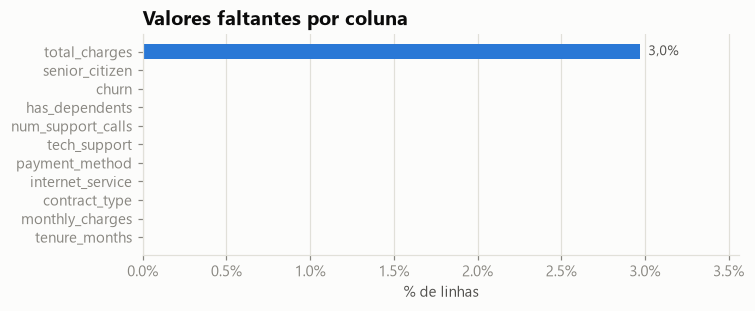

In [2]:
print(f"Dimensões brutas: {raw.shape[0]} linhas x {raw.shape[1]} colunas")
print(f"Linhas duplicadas: {raw.duplicated().sum()}")
print(f"Valores faltantes: {raw.isna().sum().sum()} (todos em total_charges)\n")
display(raw.dtypes.to_frame("dtype").T)
display(raw.describe().T.round(2))

fig, ax = plt.subplots(figsize=(7, 2.6))
missing = raw.isna().mean().sort_values()
bars = ax.barh(missing.index, missing.values, color=viz.BLUE)
ax.text(missing.max() + 0.0005, len(missing) - 1, f"{missing.max():.1%}".replace(".", ","),
        va="center", color=viz.INK_SECONDARY, fontsize=9)
ax.set(title="Valores faltantes por coluna", xlabel="% de linhas", xlim=(0, missing.max() * 1.2))
from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.grid(axis="y", visible=False)
plt.show()

**Tratamento adotado:** em vez de descartar linhas com `total_charges` nulo (como na primeira versão
do notebook, o que jogava dados bons fora), usamos a mesma função de limpeza do pipeline de treino —
`clean_data()` — que remove duplicatas e preenche nulos com a **mediana**. Assim a EDA analisa
exatamente os dados que o modelo vê.

In [3]:
df = clean_data(raw)
df["status"] = df["churn"].map({0: "Retido", 1: "Churn"})
print(f"Após limpeza: {df.shape[0]} linhas ({len(raw) - len(df)} duplicatas removidas), "
      f"{df[NUMERIC_FEATURES].isna().sum().sum()} nulos restantes")

Após limpeza: 3000 linhas (30 duplicatas removidas), 0 nulos restantes


### 1.2 Taxa geral de churn

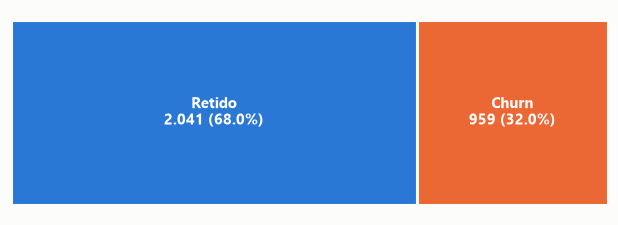

In [4]:
counts = df["status"].value_counts().reindex(STATUS_ORDER)
rate = df["churn"].mean()

fig, ax = plt.subplots(figsize=(7, 2.4))
left = 0
for status, n in counts.items():
    ax.barh(["Clientes"], [n / len(df)], left=left, color=STATUS_PALETTE[status],
            edgecolor=viz.SURFACE, linewidth=2, label=status)
    ax.text(left + n / len(df) / 2, 0, f"{status}\n{n:,} ({n / len(df):.1%})".replace(",", "."),
            ha="center", va="center", color="white", fontweight="bold")
    left += n / len(df)
ax.set(xlim=(0, 1), title=f"Taxa geral de churn: {rate:.1%}  (≈ 1 em cada {1 / rate:.0f} clientes)")
ax.axis("off")
ax.set_title(ax.get_title(), loc="left")
plt.show()

O problema é **moderadamente desbalanceado** (~32% de churn). Por isso a avaliação do modelo não usa só
*accuracy*: um modelo que sempre prevê "não cancela" acertaria ~68% e seria inútil. Usamos precision,
recall, F1 e ROC-AUC (ver `src/evaluate.py`).

## 2. Variáveis numéricas

### 2.1 Distribuições (já separadas por churn)

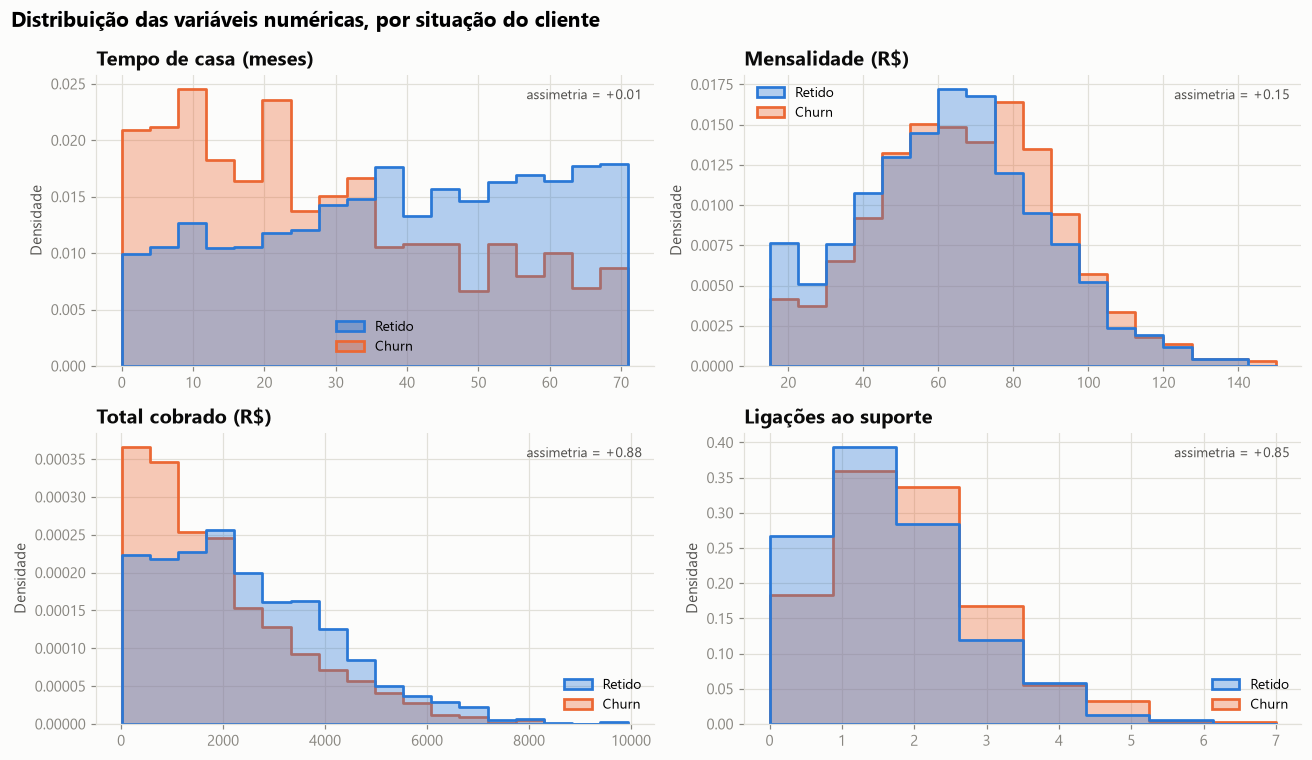

In [5]:
NUM_LABELS = {
    "tenure_months": "Tempo de casa (meses)",
    "monthly_charges": "Mensalidade (R$)",
    "total_charges": "Total cobrado (R$)",
    "num_support_calls": "Ligações ao suporte",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(data=df, x=col, hue="status", hue_order=STATUS_ORDER, palette=STATUS_PALETTE,
                 stat="density", common_norm=False, element="step", bins=18 if col != "num_support_calls" else 8,
                 alpha=0.35, linewidth=1.8, ax=ax)
    ax.set(title=NUM_LABELS[col], xlabel="", ylabel="Densidade")
    skew = df[col].skew()
    ax.text(0.98, 0.95, f"assimetria = {skew:+.2f}", transform=ax.transAxes, ha="right", va="top",
            color=viz.INK_SECONDARY, fontsize=9)
    if ax.get_legend():
        ax.get_legend().set_title(None)
fig.suptitle("Distribuição das variáveis numéricas, por situação do cliente", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

- `tenure_months` é praticamente uniforme, mas a curva laranja (churn) se concentra nos **primeiros meses**.
- `total_charges` e `num_support_calls` têm **cauda à direita** (assimetria positiva); `total_charges` é, por
  construção, quase `mensalidade × tempo de casa`.
- Em `num_support_calls` os clientes que cancelam deslocam a distribuição para **mais ligações**.

### 2.2 Numéricas vs churn

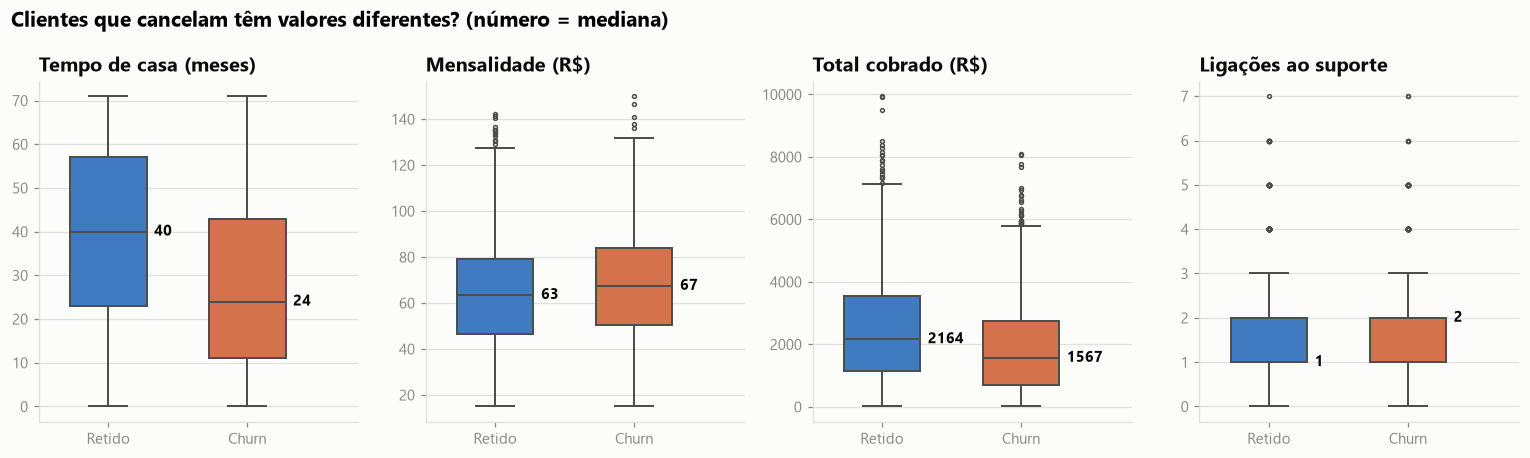

,tenure_months,monthly_charges,total_charges,num_support_calls
status,,,,
Retido,40.0,63.5,2163.9,1.0
Churn,24.0,67.4,1566.8,2.0


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=df, x="status", y=col, hue="status", order=STATUS_ORDER, palette=STATUS_PALETTE,
                width=0.55, fliersize=2.5, linewidth=1.3, ax=ax, legend=False)
    medians = df.groupby("status")[col].median()
    for i, s in enumerate(STATUS_ORDER):
        ax.text(i + 0.33, medians[s], f"{medians[s]:.0f}", va="center", ha="left", fontsize=10,
                color=viz.INK, fontweight="bold")
    ax.set_xlim(-0.5, 1.8)
    ax.set(title=NUM_LABELS[col], xlabel="", ylabel="")
    ax.grid(axis="x", visible=False)
fig.suptitle("Clientes que cancelam têm valores diferentes? (número = mediana)", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

display(df.groupby("status")[NUMERIC_FEATURES].median().loc[STATUS_ORDER].round(1))

Quem cancela tem **menos tempo de casa**, **mais ligações ao suporte** e mensalidade **ligeiramente
maior**. `total_charges` fica menor em quem cancela, mas isso é um efeito indireto do tempo de casa
(quem fica pouco tempo acumula menos cobrança).

### 2.3 Matriz de correlação

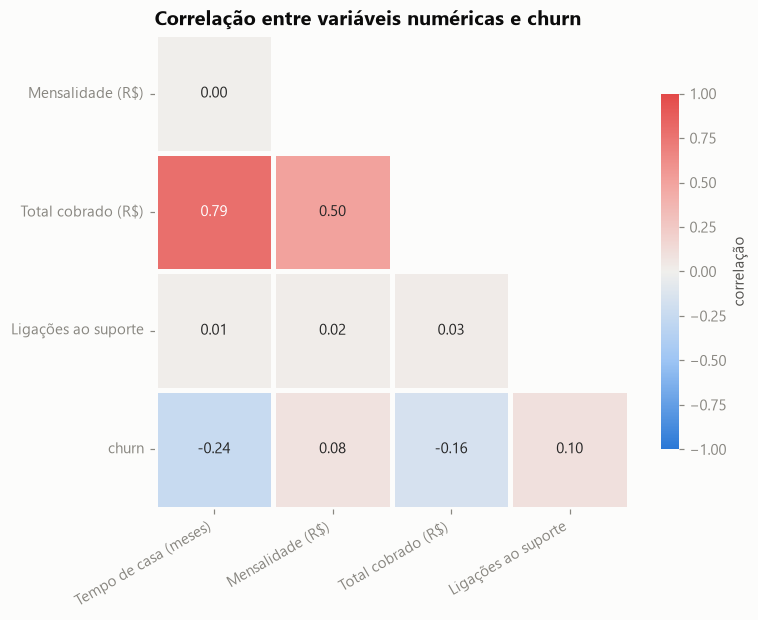

Correlação com churn (ordenada por |r|):


,r
tenure_months,-0.243
total_charges,-0.159
num_support_calls,0.101
monthly_charges,0.079


In [7]:
corr = df[NUMERIC_FEATURES + ["churn"]].corr()
# triangulo inferior sem a diagonal (que e sempre 1,00 e so polui o grafico)
lower = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(lower, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 5.6))
sns.heatmap(lower, mask=mask, cmap=viz.DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            linewidths=2, linecolor=viz.SURFACE, square=True, cbar_kws={"shrink": 0.75, "label": "correlação"},
            annot_kws={"fontsize": 10}, ax=ax)
ax.set_xticklabels([NUM_LABELS.get(c.get_text(), c.get_text()) for c in ax.get_xticklabels()], rotation=30, ha="right")
ax.set_yticklabels([NUM_LABELS.get(c.get_text(), c.get_text()) for c in ax.get_yticklabels()], rotation=0)
ax.set_title("Correlação entre variáveis numéricas e churn")
ax.grid(False)
plt.show()

print("Correlação com churn (ordenada por |r|):")
display(corr["churn"].drop("churn").sort_values(key=abs, ascending=False).round(3).to_frame("r"))

- `tenure_months` tem a correlação **negativa** mais forte com churn: quanto mais tempo de casa, menor o risco.
- `num_support_calls` correlaciona **positivamente**: mais ligações, mais insatisfação.
- `total_charges` × `tenure_months` são fortemente correlacionadas (r ≈ 0,8): são quase a mesma informação.
  Em modelos lineares isso é **multicolinearidade**; vale ficar atento ao interpretar coeficientes.

## 3. Variáveis categóricas

### 3.1 Taxa de churn por categoria

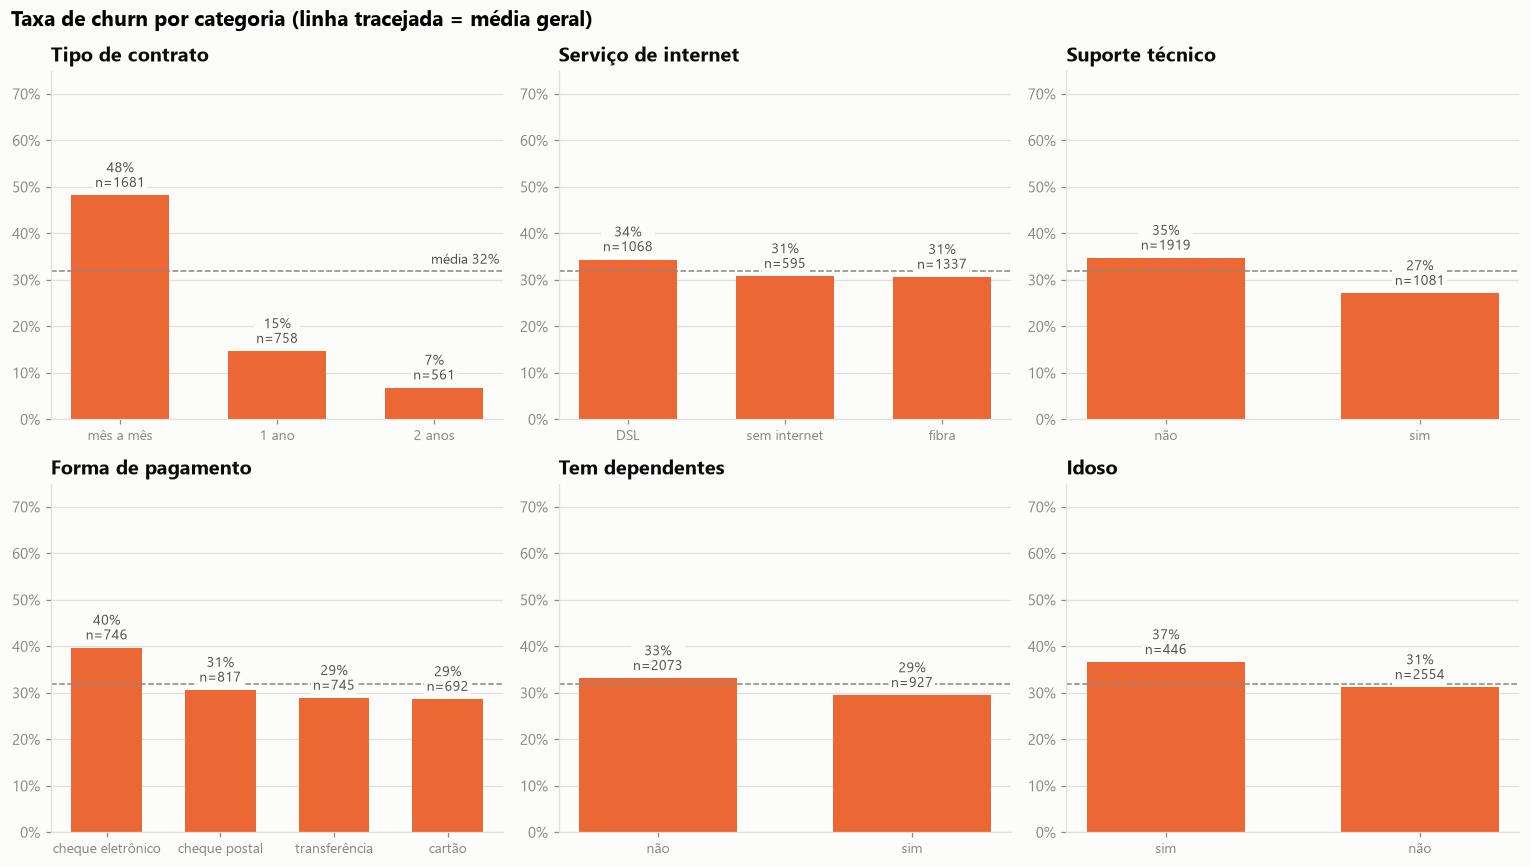

In [8]:
CAT_TITLES = {
    "contract_type": "Tipo de contrato",
    "internet_service": "Serviço de internet",
    "tech_support": "Suporte técnico",
    "payment_method": "Forma de pagamento",
    "has_dependents": "Tem dependentes",
    "senior_citizen": "Idoso",
}
VALUE_LABELS = {
    "month-to-month": "mês a mês", "one_year": "1 ano", "two_year": "2 anos",
    "fiber": "fibra", "dsl": "DSL", "none": "sem internet",
    "yes": "sim", "no": "não",
    "credit_card": "cartão", "bank_transfer": "transferência",
    "electronic_check": "cheque eletrônico", "mailed_check": "cheque postal",
    0: "não", 1: "sim",
}
overall = df["churn"].mean()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
spread = {}
for ax, col in zip(axes.ravel(), CATEGORICAL_FEATURES):
    g = df.groupby(col)["churn"].agg(rate="mean", n="size").sort_values("rate", ascending=False)
    spread[col] = g["rate"].max() - g["rate"].min()
    bars = ax.bar([VALUE_LABELS[i] for i in g.index], g["rate"], color=viz.ORANGE, width=0.62)
    ax.bar_label(bars, labels=[f"{r:.0%}\nn={n}" for r, n in zip(g["rate"], g["n"])], padding=3,
                 fontsize=9, color=viz.INK_SECONDARY,
                 bbox=dict(facecolor=viz.SURFACE, edgecolor="none", pad=1.5))
    ax.axhline(overall, color=viz.INK_MUTED, ls="--", lw=1)
    ax.set(title=CAT_TITLES[col], ylim=(0, max(0.75, g["rate"].max() + 0.12)))
    ax.grid(axis="x", visible=False)
    viz.pct_axis(ax)
    ax.tick_params(axis="x", labelsize=9)
axes[0, 0].text(0.99, overall + 0.015, f"média {overall:.0%}", transform=axes[0, 0].get_yaxis_transform(),
                ha="right", color=viz.INK_SECONDARY, fontsize=9)
fig.suptitle("Taxa de churn por categoria (linha tracejada = média geral)", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

### 3.2 Qual variável categórica mais separa os grupos?

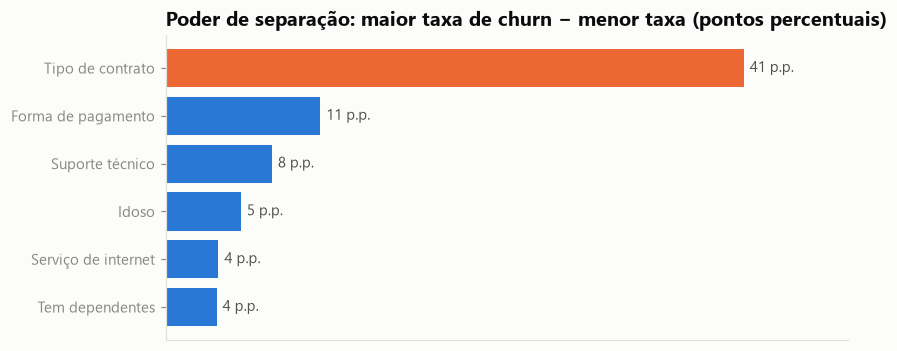

In [9]:
spread_s = pd.Series(spread).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh([CAT_TITLES[c] for c in spread_s.index], spread_s.values,
               color=[viz.ORANGE if c == spread_s.index[-1] else viz.BLUE for c in spread_s.index])
ax.bar_label(bars, labels=[f"{v * 100:.0f} p.p." for v in spread_s.values], padding=4,
             color=viz.INK_SECONDARY)
ax.set(title="Poder de separação: maior taxa de churn − menor taxa (pontos percentuais)",
       xlim=(0, spread_s.max() * 1.18))
ax.set_xticks([])
ax.grid(False)
plt.show()

**Tipo de contrato** é, com folga, a variável categórica que mais separa os grupos. Faz sentido de negócio:
quem está no contrato **mês a mês** pode sair a qualquer momento, sem multa nem fidelidade, enquanto os
contratos de 1 e 2 anos criam um compromisso (e geralmente vêm com desconto). A diferença é enorme:
**48% de churn no mês a mês contra 7% no contrato de 2 anos** (41 pontos percentuais).

Em segundo lugar vem a **forma de pagamento** (cheque eletrônico: 40% contra ~29% em cartão/transferência),
seguida de **suporte técnico** (35% sem contra 27% com) — efeitos bem menores. *Serviço de internet*,
*dependentes* e *idoso* ficam próximos da média geral (32%).

> **Atenção ao ler os gráficos:** o `n` em cada barra mostra o tamanho do grupo. Diferenças de poucos
> pontos percentuais em grupos pequenos podem ser ruído, não sinal.

## 4. Cruzamentos

### 4.1 Tempo de casa × mensalidade

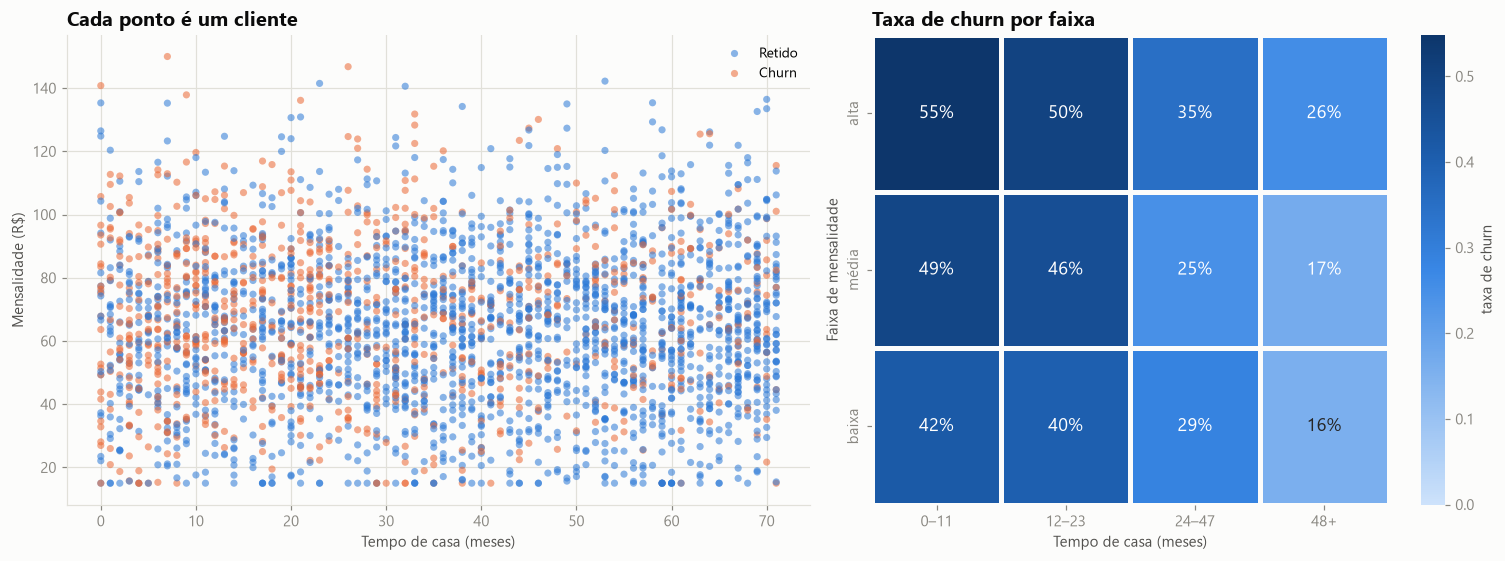

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})

ax = axes[0]
sns.scatterplot(data=df.sample(frac=1, random_state=1), x="tenure_months", y="monthly_charges", hue="status",
                hue_order=STATUS_ORDER, palette=STATUS_PALETTE, s=22, alpha=0.55, linewidth=0, ax=ax)
ax.set(title="Cada ponto é um cliente", xlabel="Tempo de casa (meses)", ylabel="Mensalidade (R$)")
ax.legend(title=None, loc="upper right")

ax = axes[1]
tenure_bins = pd.cut(df["tenure_months"], [-1, 11, 23, 47, 72], labels=["0–11", "12–23", "24–47", "48+"])
charge_bins = pd.qcut(df["monthly_charges"], 3, labels=["baixa", "média", "alta"])
pivot = df.assign(t=tenure_bins, c=charge_bins).pivot_table(index="c", columns="t", values="churn",
                                                             aggfunc="mean", observed=True)
sns.heatmap(pivot, annot=True, fmt=".0%", cmap=viz.SEQUENTIAL, vmin=0, linewidths=2,
            linecolor=viz.SURFACE, cbar_kws={"label": "taxa de churn"}, annot_kws={"fontsize": 12}, ax=ax)
ax.set(title="Taxa de churn por faixa", xlabel="Tempo de casa (meses)", ylabel="Faixa de mensalidade")
ax.grid(False)
ax.invert_yaxis()
fig.tight_layout()
plt.show()

No scatter os pontos laranja se concentram à esquerda (pouco tempo de casa), mas a nuvem tem muita
sobreposição — por isso o heatmap ao lado quantifica: o risco é **mais alto na combinação pouco tempo de
casa + mensalidade alta** e cai progressivamente conforme o cliente fica mais tempo na base.

### 4.2 Contrato × suporte técnico

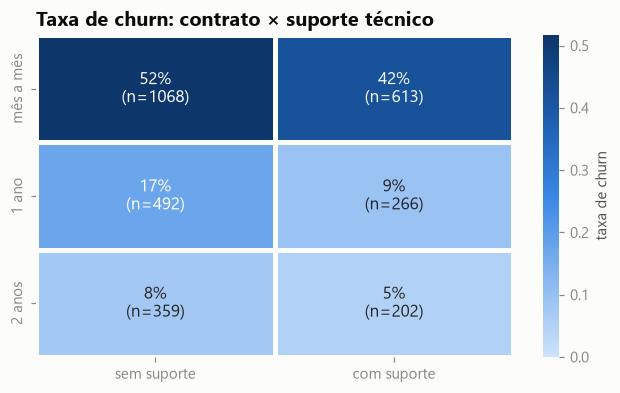

In [11]:
pivot = df.pivot_table(index="contract_type", columns="tech_support", values="churn", aggfunc="mean")
counts = df.pivot_table(index="contract_type", columns="tech_support", values="churn", aggfunc="size")
pivot.index = [VALUE_LABELS[i] for i in pivot.index]
pivot.columns = ["sem suporte" if c == "no" else "com suporte" for c in pivot.columns]
annot = pivot.map(lambda v: f"{v:.0%}") + "\n(n=" + counts.set_axis(pivot.index).set_axis(pivot.columns, axis=1).astype(str) + ")"

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(pivot.loc[["mês a mês", "1 ano", "2 anos"]], annot=annot.loc[["mês a mês", "1 ano", "2 anos"]], fmt="",
            cmap=viz.SEQUENTIAL, vmin=0, linewidths=2, linecolor=viz.SURFACE,
            cbar_kws={"label": "taxa de churn"}, annot_kws={"fontsize": 11}, ax=ax)
ax.set(title="Taxa de churn: contrato × suporte técnico", xlabel="", ylabel="")
ax.grid(False)
plt.show()

### 4.3 Ligações ao suporte e tempo de casa

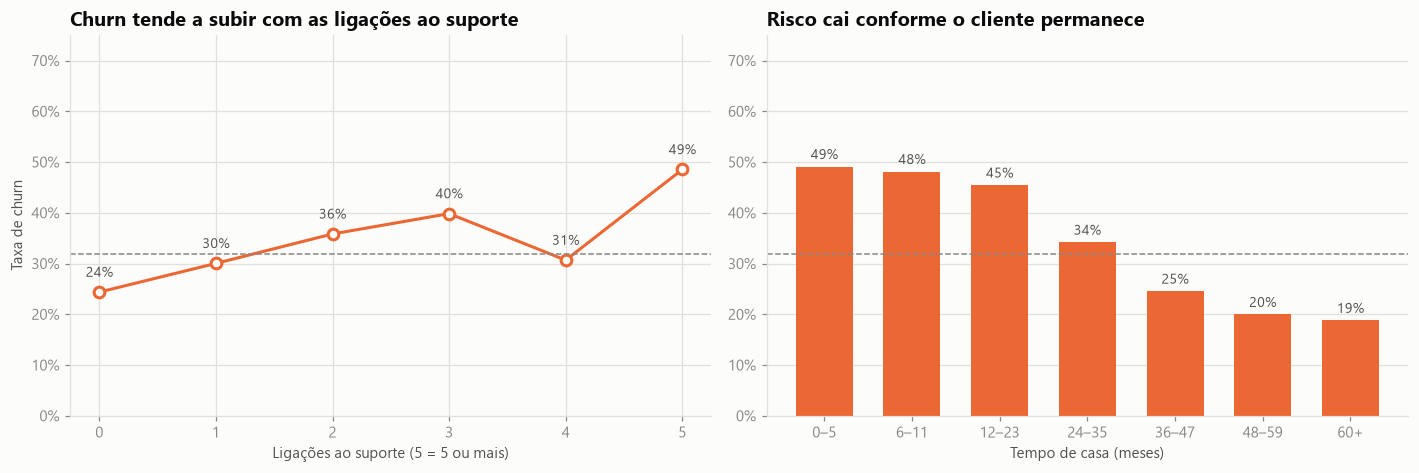

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
calls = df.assign(calls=df["num_support_calls"].clip(upper=5)).groupby("calls")["churn"].agg(["mean", "size"])
ax.plot(calls.index, calls["mean"], color=viz.ORANGE, marker="o", ms=7, mfc=viz.SURFACE, mew=2)
for x, (m, n) in calls.iterrows():
    ax.annotate(f"{m:.0%}", (x, m), textcoords="offset points", xytext=(0, 10), ha="center",
                fontsize=9, color=viz.INK_SECONDARY)
ax.axhline(overall, color=viz.INK_MUTED, ls="--", lw=1)
ax.set(title="Churn tende a subir com as ligações ao suporte", xlabel="Ligações ao suporte (5 = 5 ou mais)",
       ylabel="Taxa de churn", ylim=(0, 0.75), xticks=calls.index)
viz.pct_axis(ax)

ax = axes[1]
bands = pd.cut(df["tenure_months"], [-1, 5, 11, 23, 35, 47, 59, 72],
               labels=["0–5", "6–11", "12–23", "24–35", "36–47", "48–59", "60+"])
t = df.groupby(bands, observed=True)["churn"].mean()
bars = ax.bar(t.index.astype(str), t.values, color=viz.ORANGE, width=0.65)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in t.values], padding=3, color=viz.INK_SECONDARY, fontsize=9)
ax.axhline(overall, color=viz.INK_MUTED, ls="--", lw=1)
ax.set(title="Risco cai conforme o cliente permanece", xlabel="Tempo de casa (meses)", ylim=(0, 0.75))
ax.grid(axis="x", visible=False)
viz.pct_axis(ax)
fig.tight_layout()
plt.show()

## 5. Receita em risco

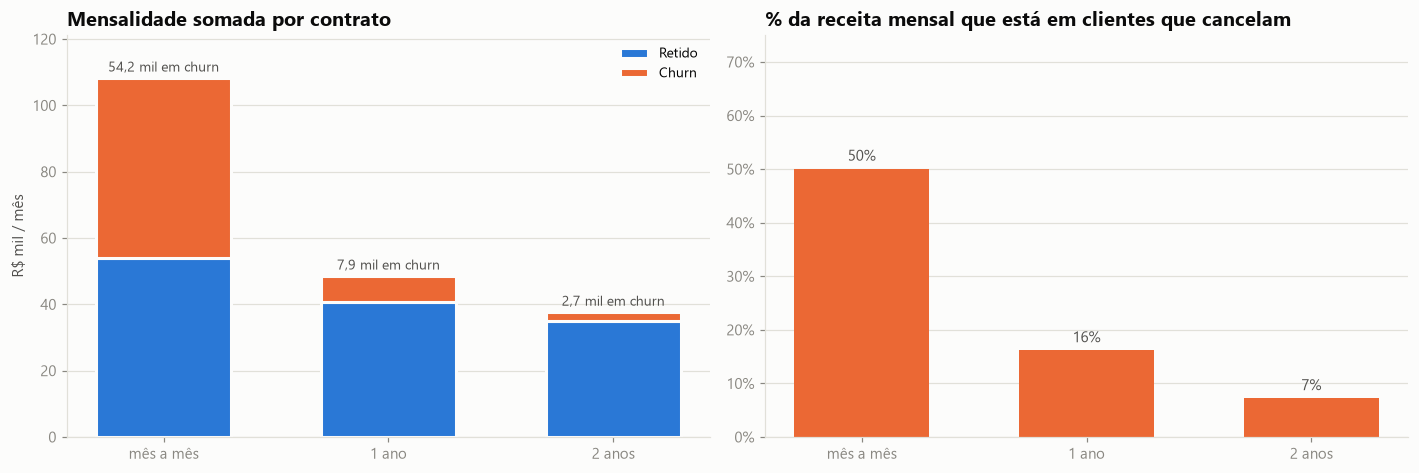

Receita mensal em clientes que cancelam: R$ 64.804 (33,4% do total)
84% dessa receita perdida vem de contratos mês a mês.


In [13]:
revenue = df.groupby(["contract_type", "status"])["monthly_charges"].sum().unstack().fillna(0)
revenue = revenue.loc[["month-to-month", "one_year", "two_year"]]
total_rev = revenue.to_numpy().sum()
lost = revenue["Churn"].sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
labels = [VALUE_LABELS[i] for i in revenue.index]
ax.bar(labels, revenue["Retido"] / 1000, color=viz.BLUE, width=0.6, label="Retido", edgecolor=viz.SURFACE, linewidth=2)
bars = ax.bar(labels, revenue["Churn"] / 1000, bottom=revenue["Retido"] / 1000, color=viz.ORANGE, width=0.6,
              label="Churn", edgecolor=viz.SURFACE, linewidth=2)
totals = revenue.sum(axis=1) / 1000
for i, (tot, ch) in enumerate(zip(totals, revenue["Churn"] / 1000)):
    ax.text(i, tot + 2, f"{ch:.1f} mil em churn".replace(".", ","), ha="center",
            color=viz.INK_SECONDARY, fontsize=9)
ax.set(title="Mensalidade somada por contrato", ylabel="R$ mil / mês", ylim=(0, totals.max() * 1.12))
ax.legend()
ax.grid(axis="x", visible=False)

ax = axes[1]
share = (revenue["Churn"] / revenue.sum(axis=1))
bars = ax.bar(labels, share, color=viz.ORANGE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in share], padding=3, color=viz.INK_SECONDARY)
ax.set(title="% da receita mensal que está em clientes que cancelam", ylim=(0, 0.75))
ax.grid(axis="x", visible=False)
viz.pct_axis(ax)
fig.tight_layout()
plt.show()

mtm_share = revenue.loc["month-to-month", "Churn"] / lost
print(f"Receita mensal em clientes que cancelam: R$ {lost:,.0f} ({lost / total_rev:.1%} do total)"
      .replace(",", "X").replace(".", ",").replace("X", "."))
print(f"{mtm_share:.0%} dessa receita perdida vem de contratos mês a mês.")

## 6. Resumo de negócio

### Principais insights

1. **O contrato mês a mês concentra o problema.** 56% dos clientes estão nele e a taxa de churn é de **48%**
   (1 ano: 15%; 2 anos: 7%). Esse grupo responde por **84% da receita mensal que sai** da empresa.
2. **Os primeiros 12 meses são a janela crítica.** O churn passa de ~49% nos 6 primeiros meses para ~19% depois
   de 5 anos de casa. Quem está no mês a mês *e* tem menos de 1 ano de casa cancela em **70%** dos casos.
3. **Suporte técnico ajuda, mas menos que o contrato.** Sem suporte, 35% cancelam (com suporte, 27%).
   Mês a mês sem suporte é o perfil de maior risco (**52%**); contrato de 2 anos com suporte é o mais seguro (**5%**).
4. **Ligações ao suporte são um sinal de alerta.** A taxa vai de 24% (nenhuma ligação) a 49% (5 ou mais) —
   com ruído no meio, mas a tendência é clara. Vale um contato proativo a quem liga repetidas vezes.
5. **Pagamento por cheque eletrônico** tem churn de 40%, contra ~29% em cartão e transferência: incentivar o
   débito automático pode funcionar como ação barata de retenção.

### Ações sugeridas

- Oferecer desconto/benefício para migrar clientes do mês a mês para contratos de 12 meses (principalmente
  nos primeiros meses de casa).
- Criar uma régua de onboarding focada nos 6 primeiros meses.
- Acionar o time de retenção quando o cliente chegar a 3+ ligações ao suporte.
- Usar o modelo (`/predict`, `churn_scored.csv`) para ordenar a fila de contato por probabilidade de churn.

> Os dados são sintéticos: os padrões refletem as regras do gerador (`data/generate_data.py`), não um
> negócio real. O método de análise, porém, se aplica igual a um dataset real.